# 06 — FD001 anomaly detection

Compare Isolation Forest (fast per-cycle baseline), a dense window autoencoder
(main experimental model), and mean squared standardized sensor deviation (simple
z-score baseline). The autoencoder reconstructs an ordered 30-by-13 window through
an 8-dimensional bottleneck; it can use temporal patterns but is not recurrent.
Neither architecture is assumed to win before evaluation.

**Protocol fixed before test evaluation:**
- Use the existing 80/20 training/validation engine IDs. Fit normality on cycles
  1–50 of training engines only. This is a health assumption, not known health;
  it deliberately avoids selecting normal data with future failure labels.
- Fit StandardScaler on those healthy training rows only. Use healthy validation
  windows for early stopping. No RUL enters model fitting or reconstruction loss.
- Primary threshold: 98th percentile of smoothed healthy validation scores (an
  empirical ~2% calibration target, not a guarantee of future false-positive rate).
  Compare a validation-only threshold maximizing sustained-alert F1 at RUL <= 30.
- Score causally, smooth over five past/current scores, then require three
  consecutive exceedances. Never smooth across engines or backdate an alert.
- Evaluate on common cycles >= 30 for all detectors; first 29 cycles are warm-up.
  Keep raw per-cycle scores too, because smoothing can hide isolated spikes.
- Failure-derived pseudo-labels are RUL <= 30, with sensitivity at 15 and 50.
  Report healthy-period FPR and a separate RUL > 125 proxy FPR. The 125 cutoff is
  an evaluation convention matching the LSTM cap, not the definition used to fit.
- FD001 only. Do not apply this scaler/detector to FD002/FD004 without regime-aware
  preprocessing and new calibration. Failure-window pseudo-labels do not establish
  accuracy on actual injected spikes, sensor faults or operating-regime changes.

The test truth file is loaded only after fitting and freezing thresholds.
Scores are anomaly measures, not probabilities of failure.

In [1]:
from pathlib import Path

# Locate the project whether the kernel starts in the root or notebooks/.
PROJECT_ROOT = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / 'requirements.txt').is_file()
     and (folder / 'notebooks').is_dir()
     and (folder / 'README.md').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError('Start this notebook from inside the Predictive maintenance for IoT project.')
RAW_DATA_DIR = PROJECT_ROOT / 'data' / 'raw' / 'cmapss'
PROCESSED_DATA_DIR = PROJECT_ROOT / 'data' / 'processed'
MODELS_DIR = PROJECT_ROOT / 'models'
FIGURES_DIR = PROJECT_ROOT / 'reports' / 'figures'
TABLES_DIR = PROJECT_ROOT / 'reports' / 'tables'
print(f'Project root: {PROJECT_ROOT}')

Project root: C:\Users\Zohair\Desktop\Predictive maintenance for IoT


In [2]:
import sys
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_curve, average_precision_score
from IPython.display import display
from predictive_maintenance.anomaly import (
    ALGORITHMS, validate_frame, windows, score_cycles, apply_threshold,
    evaluate, select_thresholds, lead_times,
)

SEED, WINDOW, HEALTHY_END, SMOOTHING, CONSECUTIVE = 42, 30, 50, 5, 3
tf.keras.utils.set_random_seed(SEED)
MODEL_DIR = MODELS_DIR / 'anomaly_fd001'
FIGURE_DIR = FIGURES_DIR / 'anomaly_fd001'
TABLE_DIR = TABLES_DIR / 'anomaly_fd001'
for directory in [MODEL_DIR, FIGURE_DIR, TABLE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
split = json.loads((PROCESSED_DATA_DIR / 'lstm_fd001' / 'metadata.json').read_text())
SENSORS = split['sensor_names']
COLUMNS = ['unit_number', 'time_in_cycles', 'setting_1', 'setting_2', 'setting_3'] + [f's_{i}' for i in range(1, 22)]
raw = pd.read_csv(RAW_DATA_DIR / 'train_FD001.txt', sep=r'\s+', header=None, names=COLUMNS)
train = validate_frame(raw[raw.unit_number.isin(split['train_units'])], SENSORS)
validation = validate_frame(raw[raw.unit_number.isin(split['val_units'])], SENSORS)
assert set(train.unit_number).isdisjoint(validation.unit_number)
healthy_train = train[train.time_in_cycles <= HEALTHY_END]
scaler = StandardScaler().fit(healthy_train[SENSORS])
train_scaled = scaler.transform(train[SENSORS]).astype(np.float32)
val_scaled = scaler.transform(validation[SENSORS]).astype(np.float32)
train_windows, train_ends = windows(train, train_scaled, WINDOW)
val_windows, val_ends = windows(validation, val_scaled, WINDOW)
train_healthy_windows = train_windows[train.loc[train_ends, 'time_in_cycles'].to_numpy() <= HEALTHY_END]
val_healthy_windows = val_windows[validation.loc[val_ends, 'time_in_cycles'].to_numpy() <= HEALTHY_END]
assert train_healthy_windows.shape == (80 * 21, 390)
assert val_healthy_windows.shape == (20 * 21, 390)
print(f'Healthy training rows: {len(healthy_train)}; healthy windows: {len(train_healthy_windows)}')
print(f'Healthy validation windows: {len(val_healthy_windows)}; engine split: 80/20')

Healthy training rows: 4000; healthy windows: 1680
Healthy validation windows: 420; engine split: 80/20


## Train without failure labels

Isolation Forest uses 200 trees and the conventional 2% contamination setting.
Its native unsmoothed threshold is reported separately from our calibrated,
smoothed-score threshold. The autoencoder uses MSE reconstruction loss, early
stopping and best-checkpoint saving on healthy validation windows only.

Autoencoder epochs: 25; best validation reconstruction MSE: 0.4935


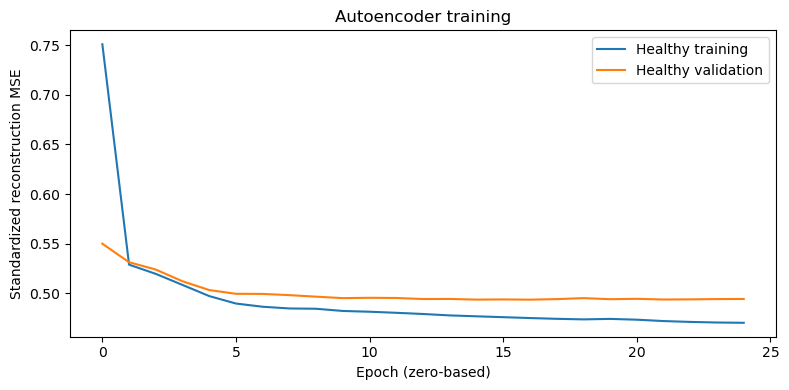

In [3]:
forest = IsolationForest(n_estimators=200, contamination=0.02, random_state=SEED, n_jobs=-1)
forest.fit(scaler.transform(healthy_train[SENSORS]).astype(np.float32))
autoencoder = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(WINDOW * len(SENSORS),)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(8, activation='linear', name='bottleneck'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(WINDOW * len(SENSORS), activation='linear'),
])
autoencoder.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss='mse')
history = autoencoder.fit(
    train_healthy_windows, train_healthy_windows,
    validation_data=(val_healthy_windows, val_healthy_windows),
    epochs=80, batch_size=64, verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
               tf.keras.callbacks.ModelCheckpoint(str(MODEL_DIR / 'best_autoencoder.keras'), monitor='val_loss', save_best_only=True)],
)
print(f'Autoencoder epochs: {len(history.history["loss"])}; best validation reconstruction MSE: {min(history.history["val_loss"]):.4f}')
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history.history['loss'], label='Healthy training')
ax.plot(history.history['val_loss'], label='Healthy validation')
ax.set(xlabel='Epoch (zero-based)', ylabel='Standardized reconstruction MSE', title='Autoencoder training')
ax.legend(); fig.tight_layout()
fig.savefig(FIGURE_DIR / 'autoencoder_training.png', dpi=150)
plt.show()

## Freeze thresholds on validation engines

For every candidate threshold, F1 refers to three-consecutive-cycle alerts.
Validation scores used for selection are development results, not independent
performance estimates. Both threshold policies are fixed before test evaluation.

In [4]:
validation_scores = score_cycles(validation, SENSORS, scaler, forest, autoencoder, WINDOW, SMOOTHING)
validation_rul = validation.groupby('unit_number').time_in_cycles.transform('max') - validation.time_in_cycles
thresholds, validation_rows = {}, []
for name in ALGORITHMS:
    thresholds[name], trials = select_thresholds(validation_scores, validation_rul, name, CONSECUTIVE)
    trials.to_csv(TABLE_DIR / f'{name}_validation_threshold_search.csv', index=False)
    for policy, threshold in thresholds[name].items():
        validation_rows.append({'model': name, 'policy': policy, 'threshold': threshold,
            **evaluate(validation_scores, validation_rul, name, threshold)})
validation_report = pd.DataFrame(validation_rows)
validation_report.to_csv(TABLE_DIR / 'validation_metrics.csv', index=False)
selected_model = validation_report[validation_report.policy.eq('healthy_q98')].sort_values('alert_f1', ascending=False).iloc[0]['model']
print('Selected primary detector using validation alert F1:', selected_model)
display(validation_report[['model', 'policy', 'threshold', 'alert_f1', 'healthy_alert_fpr']])
config = {
    'dataset': 'FD001', 'seed': SEED, 'sensors': SENSORS,
    'window_length': WINDOW, 'healthy_end_cycle': HEALTHY_END,
    'smoothing': SMOOTHING, 'consecutive': CONSECUTIVE,
    'healthy_definition': 'First 50 observed cycles, assumed healthy; no RUL used for fitting',
    'thresholds': thresholds, 'primary_policy': 'healthy_q98', 'selected_model': selected_model,
    'if_native_raw_threshold': float(-forest.offset_),
    'failure_window': 30, 'sensitivity_windows': [15, 30, 50],
    'train_units': split['train_units'], 'validation_units': split['val_units'],
    'test_labels_used_for_selection': False,
    'average_precision_definition': 'Non-interpolated average precision, not trapezoidal PR area',
    'versions': {p: importlib.metadata.version(p) for p in ['tensorflow','scikit-learn','numpy','pandas']},
}
# Freeze deployable artifacts before loading test truth.
autoencoder.save(MODEL_DIR / 'autoencoder.keras')
joblib.dump({'scaler': scaler, 'forest': forest}, MODEL_DIR / 'detectors.pkl')
(MODEL_DIR / 'metadata.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
(MODEL_DIR / 'history.json').write_text(json.dumps(history.history, indent=2), encoding='utf-8')

Selected primary detector using validation alert F1: autoencoder


,model,policy,threshold,alert_f1,healthy_alert_fpr
0,isolation_forest,healthy_q98,0.515704,0.666667,0.009524
1,isolation_forest,validation_f1,0.613056,0.877821,0.000000
2,autoencoder,healthy_q98,0.558858,0.710828,0.009524
3,autoencoder,validation_f1,0.576135,0.748571,0.000000
4,zscore,healthy_q98,2.300078,0.660246,0.011905
5,zscore,validation_f1,5.412437,0.891825,0.000000


1250

## Independent test evaluation and label-window sensitivity

For each test cycle, true RUL equals the supplied final RUL plus the number of
remaining observed cycles in that engine's record. Do not label the last observed
test cycle as failure. RUL is never clipped for these pseudo-labels.

Average precision (AP) summarizes the precision-recall curve; its no-skill reference
is positive prevalence, not 0.5. Report cycle flags separately from sustained alerts.
These are pooled cycle metrics, so longer records contribute more observations.
Test data are truncated: many engines never reach the chosen failure window while
observed. Missing alerts on those engines do not prove a missed future failure.

In [5]:
test = validate_frame(pd.read_csv(RAW_DATA_DIR / 'test_FD001.txt', sep=r'\s+', header=None, names=COLUMNS), SENSORS)
test_scores = score_cycles(test, SENSORS, scaler, forest, autoencoder, WINDOW, SMOOTHING)
truth = pd.read_csv(RAW_DATA_DIR / 'RUL_FD001.txt', sep=r'\s+', header=None)[0]
assert np.array_equal(np.sort(test.unit_number.unique()), np.arange(1, len(truth)+1))
final_rul = pd.Series(truth.to_numpy(), index=np.arange(1, len(truth)+1))
test_rul = test.unit_number.map(final_rul) + test.groupby('unit_number').time_in_cycles.transform('max') - test.time_in_cycles
assert test_rul.gt(0).all()
rows, leads = [], []
for name in ALGORITHMS:
    for policy, threshold in thresholds[name].items():
        flag, alert = apply_threshold(test_scores, name, threshold, CONSECUTIVE)
        test_scores[f'{name}_{policy}_flag'] = flag
        test_scores[f'{name}_{policy}_alert'] = alert
        for window in [15, 30, 50]:
            rows.append({'model': name, 'policy': policy, 'failure_window': window,
                         **evaluate(test_scores, test_rul, name, threshold, window, CONSECUTIVE)})
        lead = lead_times(test_scores, test_rul, name, threshold, CONSECUTIVE)
        lead['model'], lead['policy'] = name, policy
        leads.append(lead)
test_report = pd.DataFrame(rows)
lead_report = pd.concat(leads, ignore_index=True)
test_scores['true_rul_evaluation_only'] = test_rul.to_numpy()
test_scores['failure_window30_evaluation_only'] = test_rul.le(30).to_numpy()
test_scores.to_csv(TABLE_DIR / 'test_cycle_scores.csv', index=False)
validation_scores.assign(true_rul_evaluation_only=validation_rul).to_csv(TABLE_DIR / 'validation_cycle_scores.csv', index=False)
test_report.to_csv(TABLE_DIR / 'test_metrics.csv', index=False)
lead_report.to_csv(TABLE_DIR / 'unit_alert_lead_times.csv', index=False)
# Native 2% contamination baseline: no smoothing, no sustained-alert filtering.
valid = test_scores.time_in_cycles.ge(WINDOW)
native_flag = test_scores.isolation_forest_raw > -forest.offset_
from sklearn.metrics import f1_score
native = {'description': 'Native Isolation Forest 2% training-contamination threshold, raw cycle scores',
          'cycle_f1_rul30': float(f1_score(test_rul[valid] <= 30, native_flag[valid])),
          'healthy_cycle_fpr': float(native_flag[valid & test.time_in_cycles.le(50)].mean())}
(TABLE_DIR / 'native_isolation_forest.json').write_text(json.dumps(native, indent=2))
display(test_report[test_report.failure_window.eq(30)][['model','policy','average_precision','cycle_f1','alert_f1','healthy_cycle_fpr','healthy_alert_fpr','rul_gt125_alert_fpr']])

,model,policy,average_precision,cycle_f1,alert_f1,healthy_cycle_fpr,healthy_alert_fpr,rul_gt125_alert_fpr
1,isolation_forest,healthy_q98,0.765216,0.417986,0.455501,0.012783,0.000983,0.007989
4,isolation_forest,validation_f1,0.765216,0.679030,0.659476,0.000000,0.000000,0.000000
7,autoencoder,healthy_q98,0.614774,0.418256,0.450575,0.048673,0.037856,0.027864
10,autoencoder,validation_f1,0.614774,0.499062,0.512017,0.027532,0.021141,0.013055
13,zscore,healthy_q98,0.813548,0.423816,0.458304,0.006883,0.002458,0.005456
16,zscore,validation_f1,0.813548,0.723270,0.701695,0.000000,0.000000,0.000000


## Alert coverage and lead times

Lead time is the **true remaining cycles when the first sustained alert is issued**.
An alert earlier than RUL=30 is not automatically a false maintenance warning;
it is simply outside this chosen evaluation window. Report early alerts (>125)
separately. No-alert lead times stay missing, never zero. For truncated test records,
coverage applies only to the observed interval. Failure-window coverage is the
fraction of engines whose observed RUL reaches <=30 and receive an alert there.

,model,policy,engines,engines_with_observed_alert,engines_without_observed_alert,median_lead_time_among_alerted,early_first_alerts_rul_gt125,engines_with_observed_failure_window,failure_window_alert_coverage
0,autoencoder,healthy_q98,100,44,56,104.5,17,25,1.00
1,autoencoder,validation_f1,100,34,66,63.0,9,25,0.88
2,isolation_forest,healthy_q98,100,39,61,53.0,4,25,0.96
3,isolation_forest,validation_f1,100,19,81,29.0,0,25,0.68
4,zscore,healthy_q98,100,41,59,51.0,4,25,1.00
5,zscore,validation_f1,100,18,82,28.5,0,25,0.68


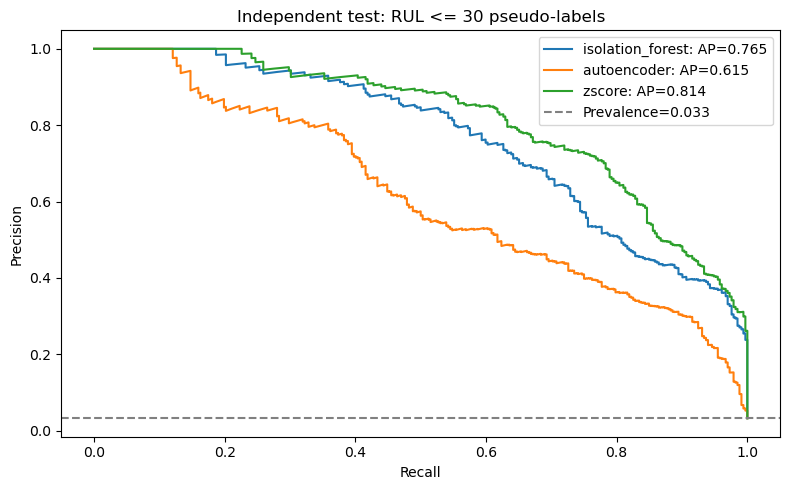

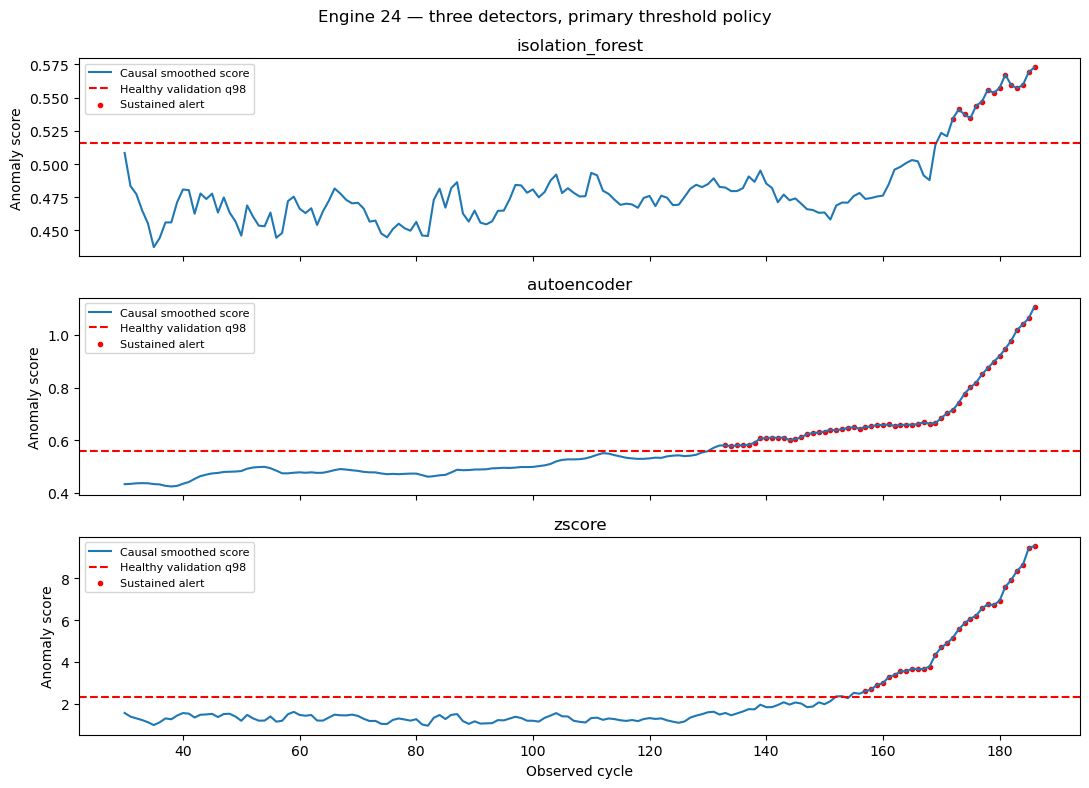

Saved artifacts: C:\Users\Zohair\Desktop\Predictive maintenance for IoT\models\anomaly_fd001
Reports: C:\Users\Zohair\Desktop\Predictive maintenance for IoT\reports\tables\anomaly_fd001
Selected by validation: autoencoder


In [6]:
lead_summary = []
for (name, policy), group in lead_report.groupby(['model','policy']):
    eligible = group.observed_failure_window
    column = f'{name}_{policy}_alert'
    window_hits = test_scores.loc[test_rul.le(30) & test_scores[column], 'unit_number'].unique()
    lead_summary.append({'model':name, 'policy':policy, 'engines':len(group),
        'engines_with_observed_alert':int(group.observed_alert.sum()),
        'engines_without_observed_alert':int((~group.observed_alert).sum()),
        'median_lead_time_among_alerted':float(group.lead_time_cycles.median()),
        'early_first_alerts_rul_gt125':int(group.lead_time_cycles.gt(125).sum()),
        'engines_with_observed_failure_window':int(eligible.sum()),
        'failure_window_alert_coverage':float(group.loc[eligible,'unit_number'].isin(window_hits).mean())})
lead_summary = pd.DataFrame(lead_summary)
lead_summary.to_csv(TABLE_DIR / 'alert_summary.csv', index=False)
display(lead_summary)

fig, ax = plt.subplots(figsize=(8,5))
mask = test_scores.time_in_cycles.ge(WINDOW)
y = test_rul[mask].le(30)
for name in ALGORITHMS:
    precision, recall, _ = precision_recall_curve(y, test_scores.loc[mask, f'{name}_score'])
    ap = average_precision_score(y, test_scores.loc[mask, f'{name}_score'])
    ax.plot(recall, precision, label=f'{name}: AP={ap:.3f}')
ax.axhline(y.mean(), linestyle='--', color='gray', label=f'Prevalence={y.mean():.3f}')
ax.set(xlabel='Recall', ylabel='Precision', title='Independent test: RUL <= 30 pseudo-labels')
ax.legend(); fig.tight_layout(); fig.savefig(FIGURE_DIR / 'precision_recall.png', dpi=150)
plt.show()

# Fixed illustration engine, chosen before viewing performance.
unit = 24
subset = test_scores[test_scores.unit_number.eq(unit)]
fig, axes = plt.subplots(3,1,figsize=(11,8),sharex=True)
for ax,name in zip(axes,ALGORITHMS):
    ax.plot(subset.time_in_cycles, subset[f'{name}_score'], label='Causal smoothed score')
    ax.axhline(thresholds[name]['healthy_q98'], color='red', linestyle='--', label='Healthy validation q98')
    alerts=subset[f'{name}_healthy_q98_alert']
    ax.scatter(subset.loc[alerts,'time_in_cycles'], subset.loc[alerts,f'{name}_score'], color='red',s=9,label='Sustained alert')
    ax.set_title(name); ax.set_ylabel('Anomaly score'); ax.legend(fontsize=8)
axes[-1].set_xlabel('Observed cycle')
fig.suptitle('Engine 24 — three detectors, primary threshold policy')
fig.tight_layout(); fig.savefig(FIGURE_DIR / 'engine24_scores.png',dpi=150)
plt.show()
primary = test_report[test_report.policy.eq('healthy_q98') & test_report.failure_window.eq(30)]
(MODEL_DIR / 'metrics.json').write_text(primary.to_json(orient='records', indent=2))
print('Saved artifacts:',MODEL_DIR)
print('Reports:',TABLE_DIR)
print('Selected by validation:',selected_model)

## Reuse the trained detector

`predict_saved` accepts consecutive per-engine raw histories containing unit ID,
cycle and the 13 selected sensors. It returns every input cycle with raw/smoothed
scores, primary-policy flags and sustained alerts for all three methods. The first
29 cycles have no common evaluation score; their flags are false (warm-up, not
confirmed healthy). Pass full histories on repeated calls to preserve rolling state.

```python
from predictive_maintenance.anomaly import predict_saved
scores = predict_saved(new_sensor_history, MODELS_DIR / 'anomaly_fd001')
```

No test-driven retuning is performed. The healthy-period assumption, false-alarm
burden and failure-window sensitivity must be reviewed before connecting alerts to
a dashboard. Genuine spike detection would need separately annotated or carefully
constructed fault examples; the current evaluation measures degradation association.

References: [Isolation Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html)
and [TensorFlow autoencoder anomaly detection](https://www.tensorflow.org/tutorials/generative/autoencoder).